In [ ]:


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


In [ ]:

import pandas as pd

# Load dataset
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Display dataset dimensions
print("Dataset Shape:", df.shape)

# Display first 5 records
display(df.head())

# Check column information
df.info()

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:

# Step 4: Data quality checks

# 1. Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

# 2. Check duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# 3. Check blank values in TotalCharges
print("\nBlank TotalCharges values:")
print((df["TotalCharges"].astype(str).str.strip() == "").sum())

# 4. Check unique values in Churn
print("\nChurn categories:")
print(df["Churn"].value_counts())

# 5. Check numerical columns
print("\nNumerical summary:")
display(df[["tenure", "MonthlyCharges"]].describe())

Missing values in each column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Number of duplicate rows:
0

Blank TotalCharges values:
11

Churn categories:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Numerical summary:


,tenure,MonthlyCharges
count,7043.000000,7043.000000
mean,32.371149,64.761692
std,24.559481,30.090047
min,0.000000,18.250000
25%,9.000000,35.500000
50%,29.000000,70.350000
75%,55.000000,89.850000
max,72.000000,118.750000


In [ ]:

# Step 6: Data cleaning

# Replace blank spaces with missing values
df["TotalCharges"] = df["TotalCharges"].replace(
    r"^\s*$", pd.NA, regex=True
)

# Convert TotalCharges into numeric format
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Check missing values after conversion
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())

# Check data types
print("\nUpdated data types:")
print(df.dtypes)

# Display cleaned dataset
display(df.head())

Missing TotalCharges: 11

Updated data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:

# Step 7: Customer Churn Analysis

# Count customers by churn status
churn_counts = df["Churn"].value_counts()

print("Customer Churn Counts:")
print(churn_counts)

# Calculate churn percentage
churn_rate = (churn_counts["Yes"] / len(df)) * 100

print("\nOverall Churn Rate:", round(churn_rate, 2), "%")

# Calculate retention percentage
retention_rate = (churn_counts["No"] / len(df)) * 100

print("Customer Retention Rate:", round(retention_rate, 2), "%")

Customer Churn Counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Overall Churn Rate: 26.54 %
Customer Retention Rate: 73.46 %


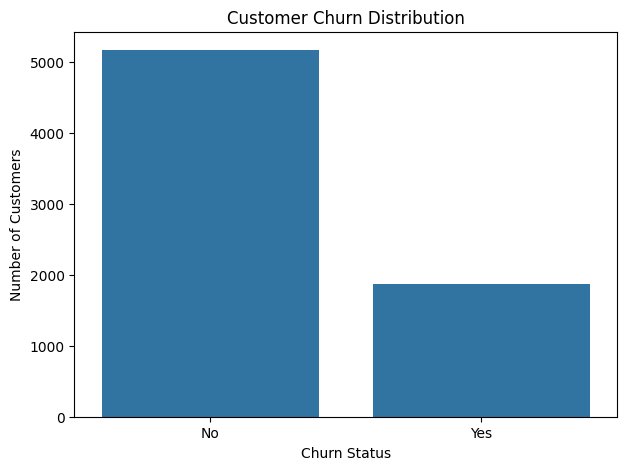

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

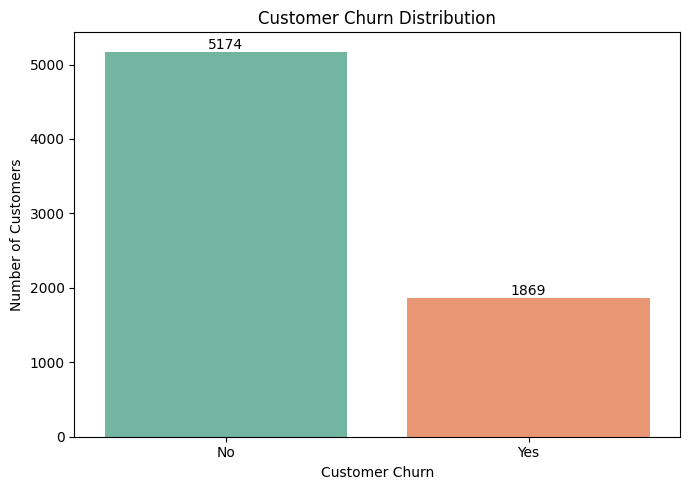

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

for bar in ax.patches:
    ax.annotate(
        f"{int(bar.get_height())}",
        (bar.get_x() + bar.get_width()/2, bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

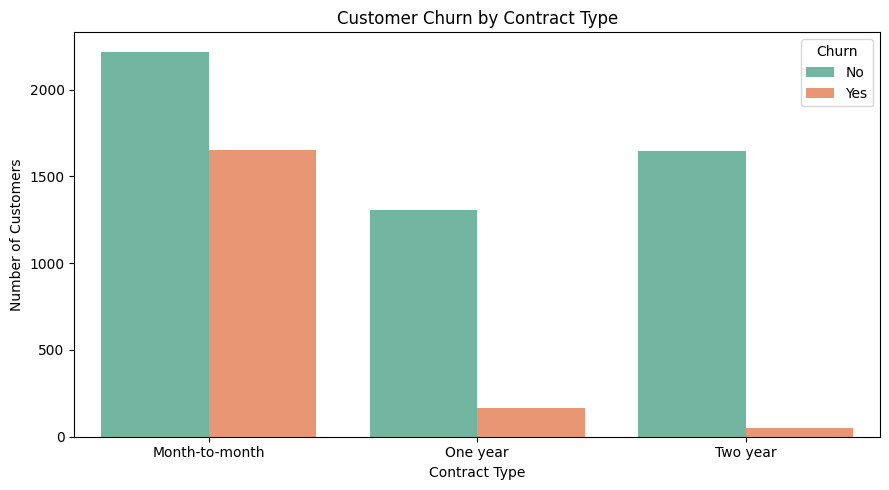

In [ ]:

# Customer churn by contract type

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn",
    palette="Set2"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.legend(title="Churn")

plt.tight_layout()
plt.show()

Churn Rate by Contract Type:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


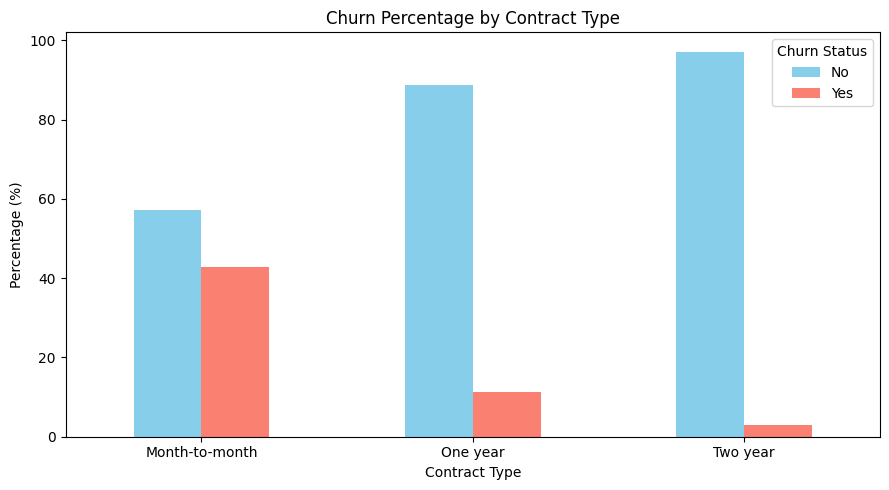

In [ ]:

# Calculate churn rate by contract type

contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn Rate by Contract Type:")
display(contract_churn.round(2))

# Visualize churn percentage
contract_churn.plot(
    kind="bar",
    figsize=(9, 5),
    color=["skyblue", "salmon"]
)

plt.title("Churn Percentage by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn Status")
plt.tight_layout()
plt.show()

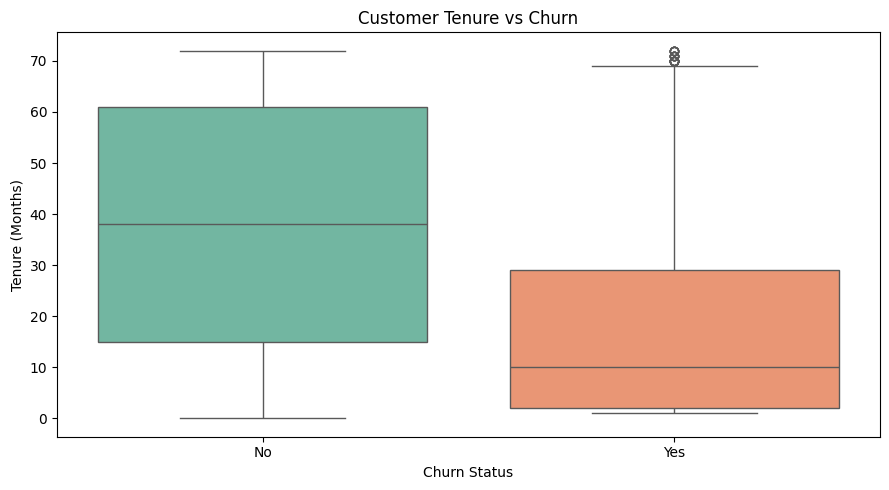

Average Tenure by Churn Status:


,tenure
Churn,
No,37.57
Yes,17.98


In [ ]:

# Analyze customer tenure by churn status

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")

plt.tight_layout()
plt.show()

# Average tenure by churn status
print("Average Tenure by Churn Status:")
display(df.groupby("Churn")["tenure"].mean().round(2))

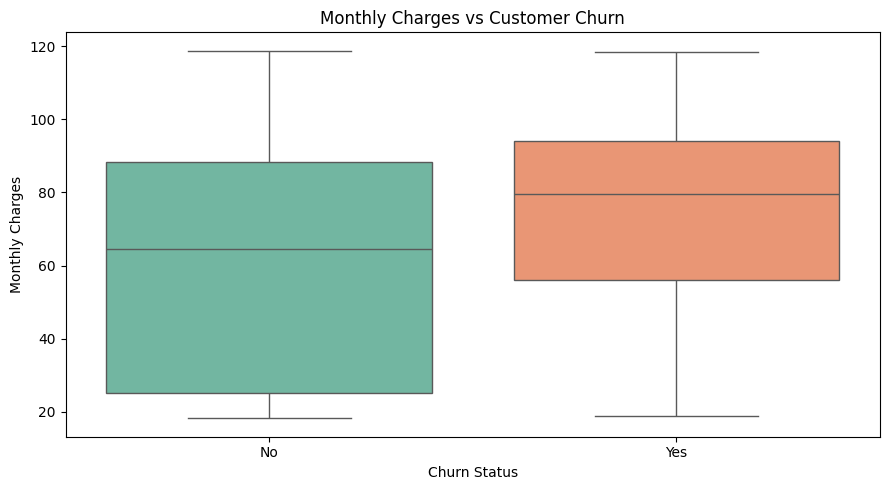

Average Monthly Charges by Churn:


,MonthlyCharges
Churn,
No,61.27
Yes,74.44


In [ ]:

# Analyze monthly charges by churn status

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

# Average monthly charges
print("Average Monthly Charges by Churn:")
display(
    df.groupby("Churn")["MonthlyCharges"]
    .mean()
    .round(2)
)

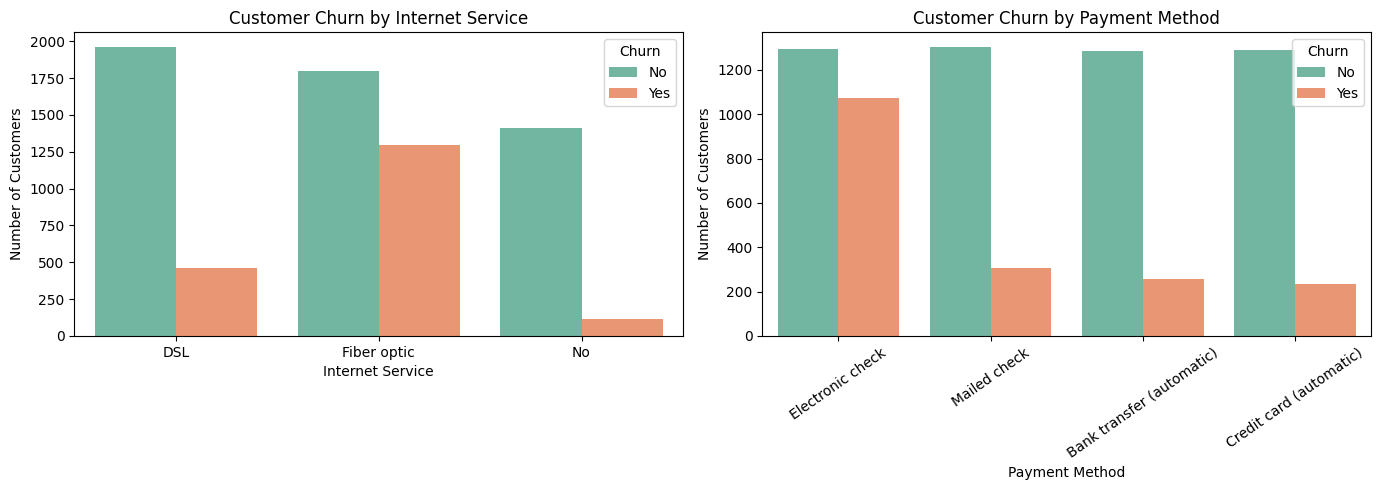

In [ ]:

# Churn by Internet Service

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn",
    ax=axes[0],
    palette="Set2"
)

axes[0].set_title("Customer Churn by Internet Service")
axes[0].set_xlabel("Internet Service")
axes[0].set_ylabel("Number of Customers")

# Churn by Payment Method
sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn",
    ax=axes[1],
    palette="Set2"
)

axes[1].set_title("Customer Churn by Payment Method")
axes[1].set_xlabel("Payment Method")
axes[1].set_ylabel("Number of Customers")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

Churn Rate by Internet Service:


Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40



Churn Rate by Payment Method:


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


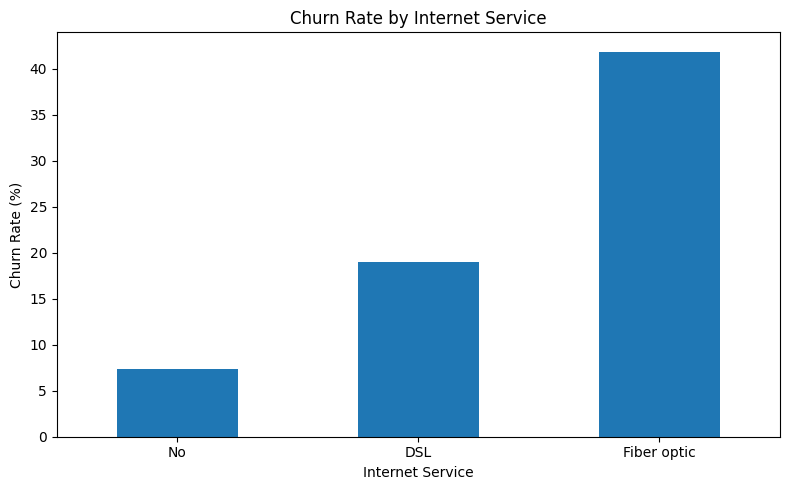

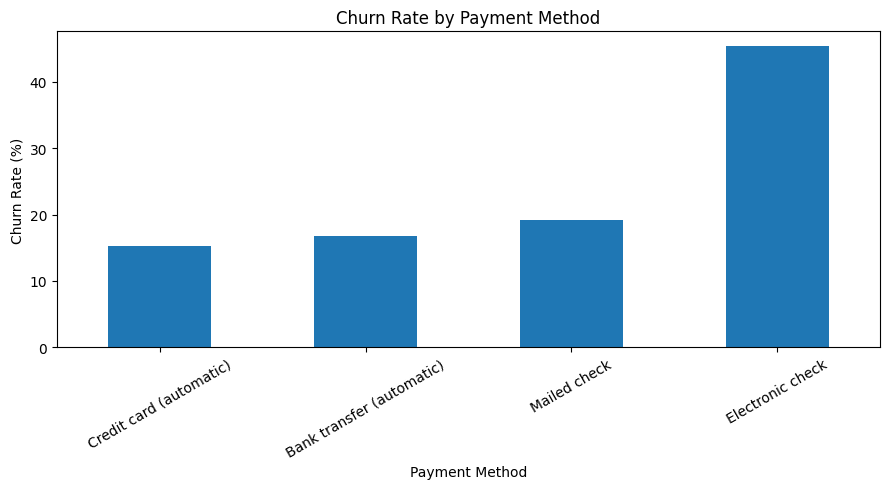

In [ ]:

# Churn rate by Internet Service
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn Rate by Internet Service:")
display(internet_churn.round(2))

# Churn rate by Payment Method
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Rate by Payment Method:")
display(payment_churn.round(2))

# Visualize Internet Service churn rate
internet_churn["Yes"].sort_values().plot(
    kind="bar",
    figsize=(8, 5),
    title="Churn Rate by Internet Service",
    ylabel="Churn Rate (%)",
    xlabel="Internet Service",
    rot=0
)
plt.tight_layout()
plt.show()

# Visualize Payment Method churn rate
payment_churn["Yes"].sort_values().plot(
    kind="bar",
    figsize=(9, 5),
    title="Churn Rate by Payment Method",
    ylabel="Churn Rate (%)",
    xlabel="Payment Method",
    rot=30
)
plt.tight_layout()
plt.show()

Churn Rate by Gender:


Churn,No,Yes
gender,,
Female,73.08,26.92
Male,73.84,26.16



Churn Rate by Senior Citizen Status:


Churn,No,Yes
SeniorCitizen,,
0,76.39,23.61
1,58.32,41.68


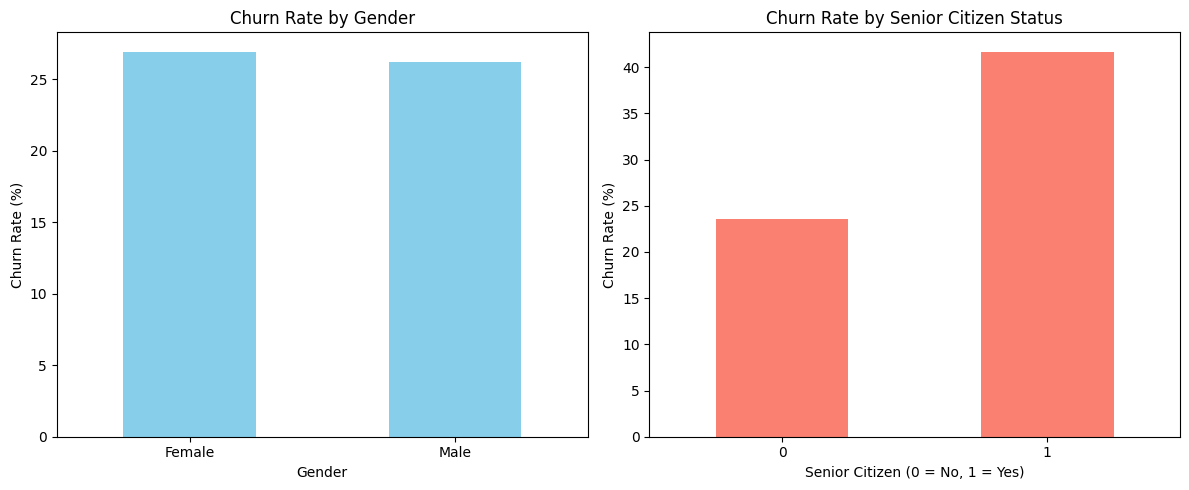

In [ ]:

# Churn rate by Gender
gender_churn = pd.crosstab(
    df["gender"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn Rate by Gender:")
display(gender_churn.round(2))

# Churn rate by Senior Citizen status
senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Rate by Senior Citizen Status:")
display(senior_churn.round(2))

# Plot gender churn
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

gender_churn["Yes"].plot(
    kind="bar", ax=axes[0], color="skyblue"
)
axes[0].set_title("Churn Rate by Gender")
axes[0].set_ylabel("Churn Rate (%)")
axes[0].set_xlabel("Gender")
axes[0].tick_params(axis="x", rotation=0)

# Plot senior citizen churn
senior_churn["Yes"].plot(
    kind="bar", ax=axes[1], color="salmon"
)
axes[1].set_title("Churn Rate by Senior Citizen Status")
axes[1].set_ylabel("Churn Rate (%)")
axes[1].set_xlabel("Senior Citizen (0 = No, 1 = Yes)")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


Churn Rate by OnlineSecurity:


Churn,No,Yes
OnlineSecurity,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61



Churn Rate by OnlineBackup:


Churn,No,Yes
OnlineBackup,,
No,60.07,39.93
No internet service,92.60,7.40
Yes,78.47,21.53



Churn Rate by DeviceProtection:


Churn,No,Yes
DeviceProtection,,
No,60.87,39.13
No internet service,92.60,7.40
Yes,77.50,22.50



Churn Rate by TechSupport:


Churn,No,Yes
TechSupport,,
No,58.36,41.64
No internet service,92.60,7.40
Yes,84.83,15.17


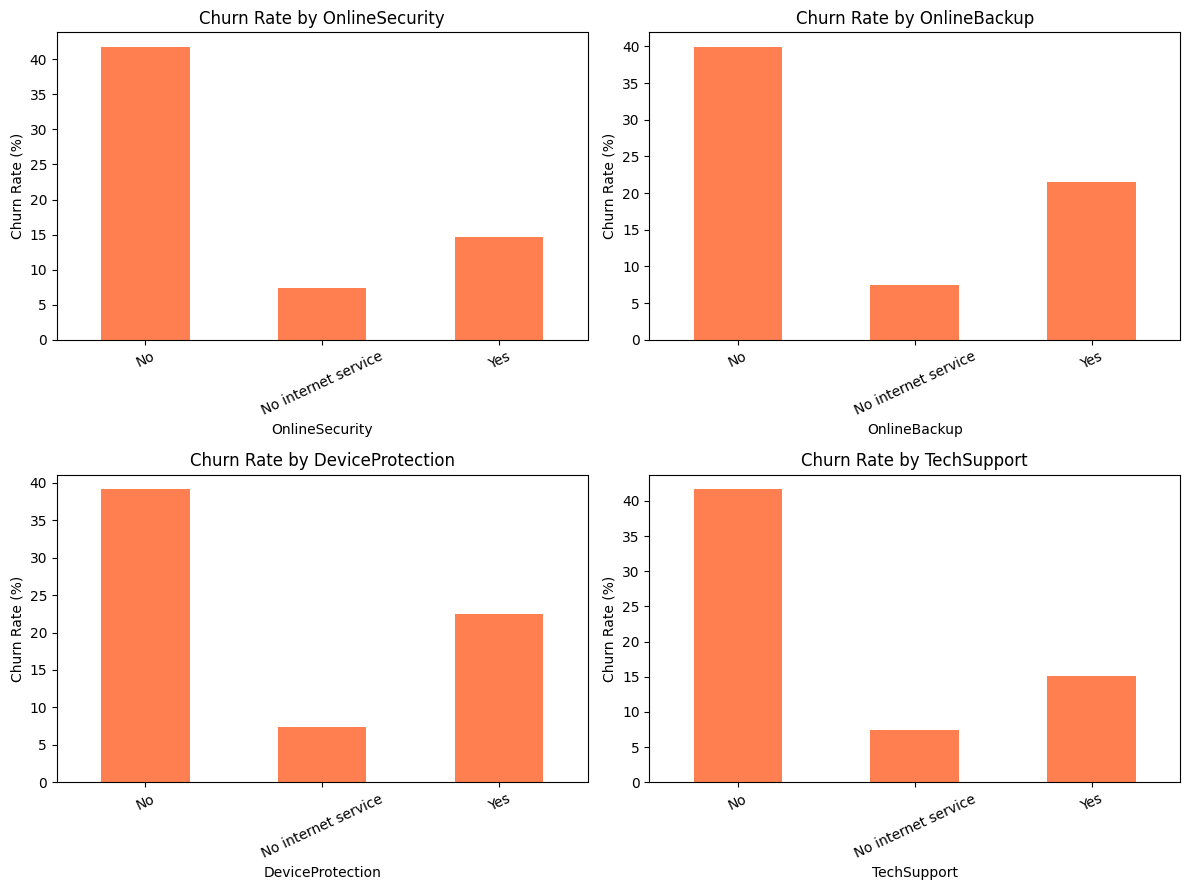

In [ ]:

# Churn rates for additional services

services = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport"
]

for service in services:
    print(f"\nChurn Rate by {service}:")

    result = pd.crosstab(
        df[service],
        df["Churn"],
        normalize="index"
    ) * 100

    display(result.round(2))

# Visualize churn rates across services
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for service, ax in zip(services, axes.flatten()):
    rate = pd.crosstab(
        df[service],
        df["Churn"],
        normalize="index"
    ) * 100

    rate["Yes"].plot(
        kind="bar",
        ax=ax,
        color="coral"
    )

    ax.set_title(f"Churn Rate by {service}")
    ax.set_ylabel("Churn Rate (%)")
    ax.set_xlabel(service)
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()


Churn Rate by Partner:


Churn,No,Yes
Partner,,
No,67.04,32.96
Yes,80.34,19.66



Churn Rate by Dependents:


Churn,No,Yes
Dependents,,
No,68.72,31.28
Yes,84.55,15.45



Churn Rate by PaperlessBilling:


Churn,No,Yes
PaperlessBilling,,
No,83.67,16.33
Yes,66.43,33.57


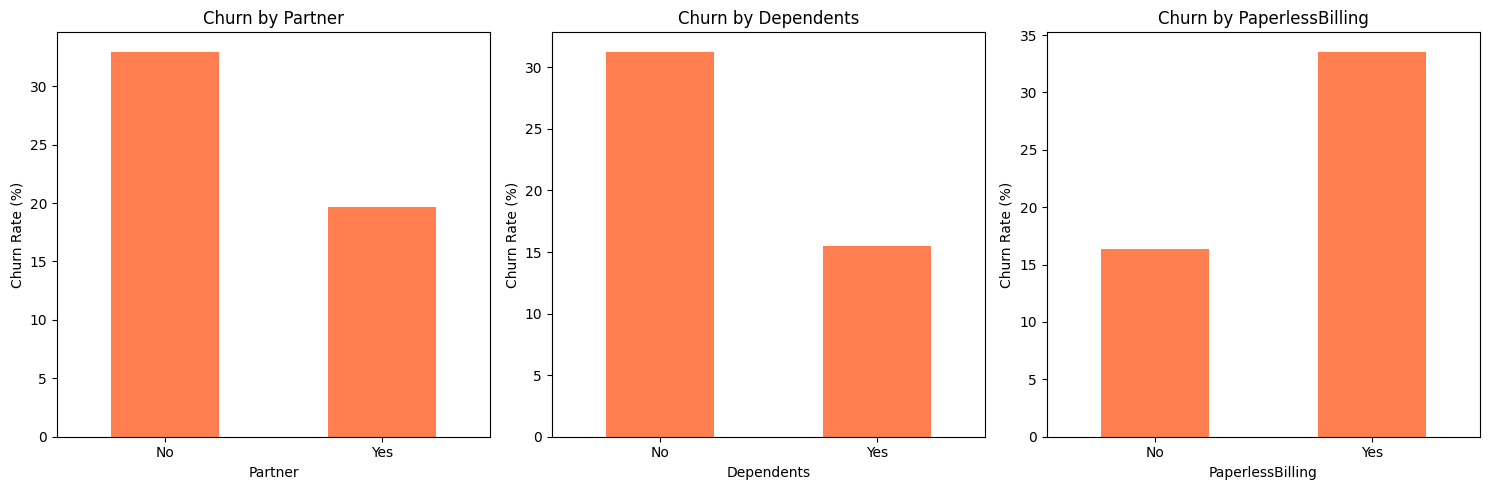

In [ ]:

# Analyze churn across customer groups

columns = ["Partner", "Dependents", "PaperlessBilling"]

for col in columns:
    print(f"\nChurn Rate by {col}:")

    result = pd.crosstab(
        df[col],
        df["Churn"],
        normalize="index"
    ) * 100

    display(result.round(2))

# Visualize the results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for col, ax in zip(columns, axes):
    rates = pd.crosstab(
        df[col],
        df["Churn"],
        normalize="index"
    ) * 100

    rates["Yes"].plot(
        kind="bar",
        ax=ax,
        color="coral"
    )

    ax.set_title(f"Churn by {col}")
    ax.set_ylabel("Churn Rate (%)")
    ax.set_xlabel(col)
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


Churn Rate by Partner:


Churn,No,Yes
Partner,,
No,67.04,32.96
Yes,80.34,19.66



Churn Rate by Dependents:


Churn,No,Yes
Dependents,,
No,68.72,31.28
Yes,84.55,15.45



Churn Rate by PaperlessBilling:


Churn,No,Yes
PaperlessBilling,,
No,83.67,16.33
Yes,66.43,33.57


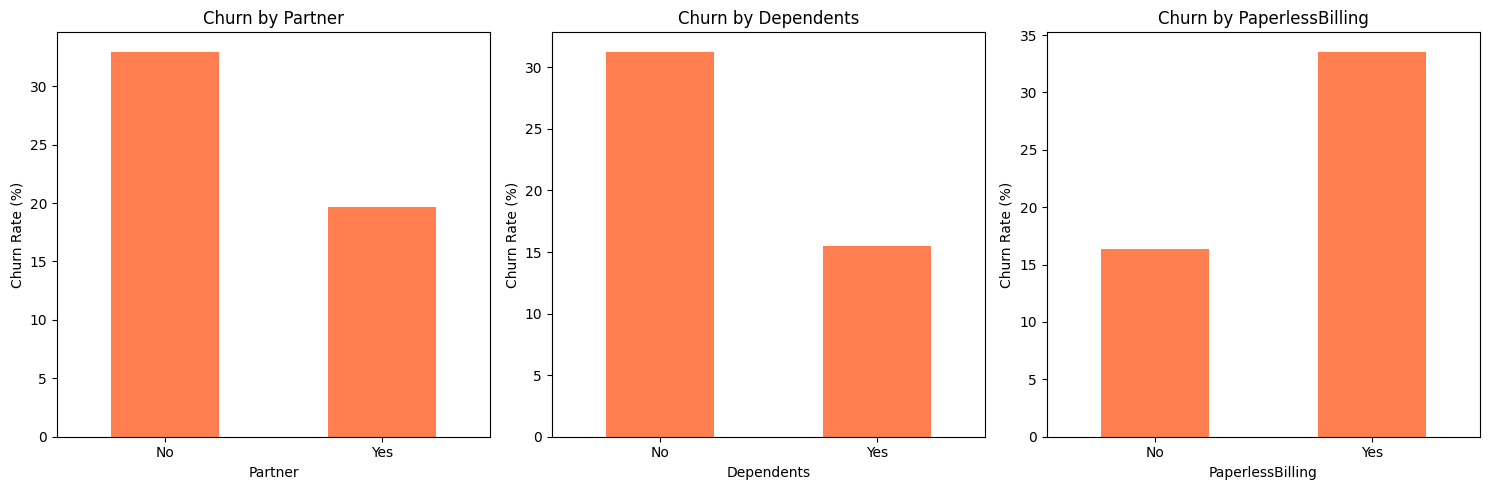

In [ ]:

# Analyze churn across customer groups

columns = ["Partner", "Dependents", "PaperlessBilling"]

for col in columns:
    print(f"\nChurn Rate by {col}:")

    result = pd.crosstab(
        df[col],
        df["Churn"],
        normalize="index"
    ) * 100

    display(result.round(2))

# Visualize the results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for col, ax in zip(columns, axes):
    rates = pd.crosstab(
        df[col],
        df["Churn"],
        normalize="index"
    ) * 100

    rates["Yes"].plot(
        kind="bar",
        ax=ax,
        color="coral"
    )

    ax.set_title(f"Churn by {col}")
    ax.set_ylabel("Churn Rate (%)")
    ax.set_xlabel(col)
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

Churn Rate by Tenure Group:


Churn,No,Yes
TenureGroup,,
New (0-12 months),52.56,47.44
Medium (13-48 months),76.36,23.64
Long-term (49-72 months),90.49,9.51


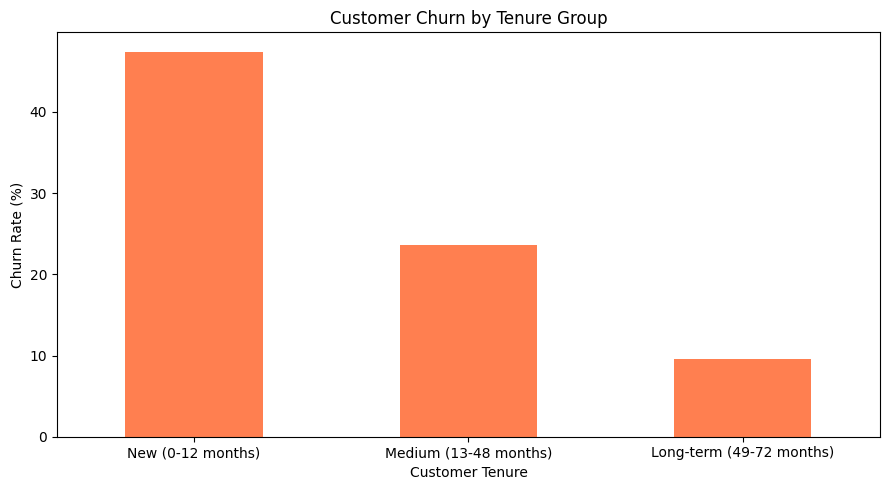

In [ ]:

# Group customers based on tenure

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 48, 72],
    labels=["New (0-12 months)",
            "Medium (13-48 months)",
            "Long-term (49-72 months)"]
)

# Calculate churn rate
tenure_churn = pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn Rate by Tenure Group:")
display(tenure_churn.round(2))

# Visualize
tenure_churn["Yes"].plot(
    kind="bar",
    figsize=(9, 5),
    color="coral"
)

plt.title("Customer Churn by Tenure Group")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Correlation Matrix:


,tenure,MonthlyCharges,TotalCharges,ChurnNumeric
tenure,1.00,0.25,0.83,-0.35
MonthlyCharges,0.25,1.00,0.65,0.19
TotalCharges,0.83,0.65,1.00,-0.20
ChurnNumeric,-0.35,0.19,-0.20,1.00


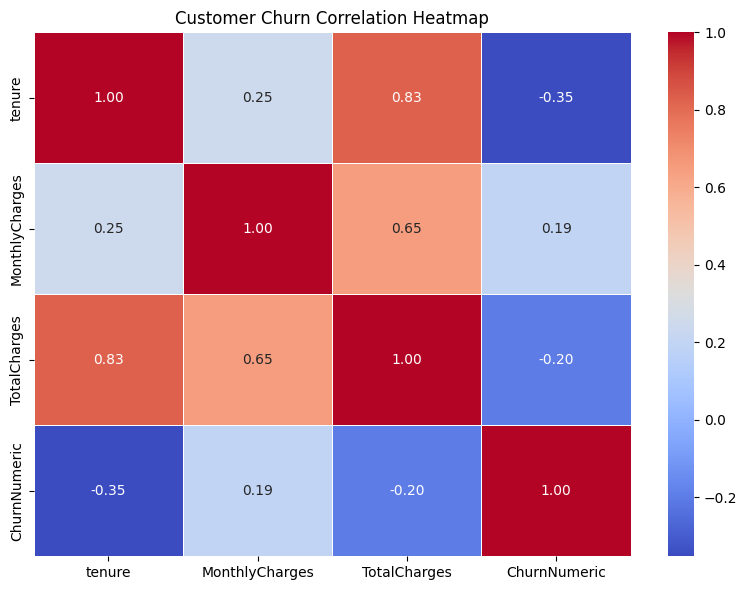

In [ ]:

# Step 18: Correlation analysis

# Convert churn into numeric values
df["ChurnNumeric"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Select numerical columns
correlation_data = df[
    ["tenure", "MonthlyCharges",
     "TotalCharges", "ChurnNumeric"]
]

# Calculate correlation
correlation = correlation_data.corr()

print("Correlation Matrix:")
display(correlation.round(2))

# Create heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Customer Churn Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:

# Step 19: Customer Churn KPI Summary

total_customers = len(df)
churned_customers = (df["Churn"] == "Yes").sum()
retained_customers = (df["Churn"] == "No").sum()

churn_rate = (churned_customers / total_customers) * 100
retention_rate = (retained_customers / total_customers) * 100

kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Churned Customers",
        "Retained Customers",
        "Churn Rate (%)",
        "Retention Rate (%)",
        "Average Tenure (Months)",
        "Average Monthly Charges",
        "Missing TotalCharges"
    ],
    "Value": [
        total_customers,
        churned_customers,
        retained_customers,
        round(churn_rate, 2),
        round(retention_rate, 2),
        round(df["tenure"].mean(), 2),
        round(df["MonthlyCharges"].mean(), 2),
        df["TotalCharges"].isna().sum()
    ]
})

display(kpi_summary)

,Metric,Value
0,Total Customers,7043.00
1,Churned Customers,1869.00
2,Retained Customers,5174.00
3,Churn Rate (%),26.54
4,Retention Rate (%),73.46
5,Average Tenure (Months),32.37
6,Average Monthly Charges,64.76
7,Missing TotalCharges,11.00


In [ ]:

# Inspect customers with missing TotalCharges

missing_rows = df[df["TotalCharges"].isna()]

print("Number of affected customers:", len(missing_rows))

display(
    missing_rows[
        ["customerID", "tenure", "MonthlyCharges",
         "TotalCharges", "Churn"]
    ]
)

Number of affected customers: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [ ]:

# Step 21: Verify and handle missing TotalCharges

missing_rows = df["TotalCharges"].isna()

print("Missing TotalCharges:", missing_rows.sum())
print("Tenure values of affected customers:")
print(df.loc[missing_rows, "tenure"].value_counts())

# Fill with zero only if all affected customers have zero tenure
if (df.loc[missing_rows, "tenure"] == 0).all():
    df.loc[missing_rows, "TotalCharges"] = 0
else:
    print("Some records need further investigation.")

# Verify cleaning
print("\nRemaining missing values:")
print(df.isnull().sum().sum())

# Export cleaned dataset
df.to_csv("Customer_Churn_Cleaned.csv", index=False)

print("\nCleaned dataset exported successfully!")

Missing TotalCharges: 11
Tenure values of affected customers:
tenure
0    11
Name: count, dtype: int64

Remaining missing values:
0

Cleaned dataset exported successfully!


In [ ]:

import sqlite3

# Create a SQLite database
conn = sqlite3.connect("customer_churn.db")

# Store cleaned dataset as a SQL table
df.to_sql(
    "customers",
    conn,
    if_exists="replace",
    index=False
)

print("Customer data successfully loaded into SQL!")

Customer data successfully loaded into SQL!


In [ ]:

query = """
SELECT
    Contract,
    COUNT(*) AS Total_Customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        AS Churned_Customers,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS Churn_Rate
FROM customers
GROUP BY Contract
ORDER BY Churn_Rate DESC;
"""

result = pd.read_sql_query(query, conn)
display(result)

,Contract,Total_Customers,Churned_Customers,Churn_Rate
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


In [ ]:

# SQL: Churn rate by tenure group

query = """
SELECT
    CASE
        WHEN tenure <= 12 THEN 'New Customers'
        WHEN tenure <= 48 THEN 'Medium-Term Customers'
        ELSE 'Long-Term Customers'
    END AS Tenure_Group,

    COUNT(*) AS Total_Customers,

    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        AS Churned_Customers,

    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS Churn_Rate

FROM customers
GROUP BY Tenure_Group
ORDER BY Churn_Rate DESC;
"""

result = pd.read_sql_query(query, conn)
display(result)

,Tenure_Group,Total_Customers,Churned_Customers,Churn_Rate
0,New Customers,2186,1037,47.44
1,Medium-Term Customers,2618,619,23.64
2,Long-Term Customers,2239,213,9.51


In [ ]:

query = """
SELECT
    COUNT(*) AS Churned_Customers,
    ROUND(SUM(MonthlyCharges), 2) AS Monthly_Revenue_At_Risk,
    ROUND(AVG(MonthlyCharges), 2) AS Average_Monthly_Charge,
    ROUND(AVG(TotalCharges), 2) AS Average_Total_Charges
FROM customers
WHERE Churn = 'Yes';
"""

result = pd.read_sql_query(query, conn)
display(result)

,Churned_Customers,Monthly_Revenue_At_Risk,Average_Monthly_Charge,Average_Total_Charges
0,1869,139130.85,74.44,1531.8


In [ ]:

query = """
SELECT
    PaymentMethod,
    COUNT(*) AS Total_Customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        AS Churned_Customers,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS Churn_Rate
FROM customers
GROUP BY PaymentMethod
ORDER BY Churn_Rate DESC;
"""

result = pd.read_sql_query(query, conn)
display(result)

,PaymentMethod,Total_Customers,Churned_Customers,Churn_Rate
0,Electronic check,2365,1071,45.29
1,Mailed check,1612,308,19.11
2,Bank transfer (automatic),1544,258,16.71
3,Credit card (automatic),1522,232,15.24


In [ ]:

query = """
SELECT
    PaymentMethod,
    COUNT(*) AS Total_Customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        AS Churned_Customers,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS Churn_Rate
FROM customers
WHERE PaymentMethod = 'Credit card (automatic)'
GROUP BY PaymentMethod;
"""

display(pd.read_sql_query(query, conn))

,PaymentMethod,Total_Customers,Churned_Customers,Churn_Rate
0,Credit card (automatic),1522,232,15.24


In [ ]:

query = """
SELECT
    Contract,
    COUNT(*) AS Total_Customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        AS Churned_Customers,
    ROUND(AVG(MonthlyCharges), 2) AS Avg_Monthly_Charges,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS Churn_Rate
FROM customers
GROUP BY Contract
ORDER BY Churn_Rate DESC;
"""

result = pd.read_sql_query(query, conn)
display(result)

,Contract,Total_Customers,Churned_Customers,Avg_Monthly_Charges,Churn_Rate
0,Month-to-month,3875,1655,66.40,42.71
1,One year,1473,166,65.05,11.27
2,Two year,1695,48,60.77,2.83


In [ ]:

# Export contract analysis results
result.to_csv("Contract_Churn_SQL_Analysis.csv", index=False)

# Export payment method analysis
payment_result = pd.read_sql_query("""
SELECT
    PaymentMethod,
    COUNT(*) AS Total_Customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS Churned_Customers,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS Churn_Rate
FROM customers
GROUP BY PaymentMethod;
""", conn)

payment_result.to_csv("Payment_Method_SQL_Analysis.csv", index=False)

print("SQL analysis files exported successfully!")

SQL analysis files exported successfully!


In [ ]:

# Step 29: Create an interactive dashboard

!pip -q install plotly

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd

# Calculate churn rates
contract_rate = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

payment_rate = (
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

df["Tenure_Group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 48, 72],
    labels=["New", "Medium-term", "Long-term"]
)

tenure_rate = (
    df.groupby("Tenure_Group", observed=False)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

# Create dashboard layout
fig = make_subplots(
    rows=3, cols=2,
    specs=[
        [{"type": "indicator"}, {"type": "indicator"}],
        [{"type": "bar"}, {"type": "bar"}],
        [{"type": "bar"}, {"type": "box"}]
    ],
    subplot_titles=(
        "Total Customers", "Overall Churn Rate",
        "Churn by Contract", "Churn by Payment Method",
        "Churn by Tenure", "Monthly Charges by Churn"
    ),
    vertical_spacing=0.13
)

# KPI cards
fig.add_trace(go.Indicator(
    mode="number",
    value=len(df)
), row=1, col=1)

fig.add_trace(go.Indicator(
    mode="number",
    value=round((df["Churn"] == "Yes").mean() * 100, 2),
    number={"suffix": "%"}
), row=1, col=2)

# Contract chart
fig.add_trace(go.Bar(
    x=contract_rate.index.astype(str),
    y=contract_rate.values,
    name="Contract churn rate"
), row=2, col=1)

# Payment chart
fig.add_trace(go.Bar(
    x=payment_rate.index.astype(str),
    y=payment_rate.values,
    name="Payment churn rate"
), row=2, col=2)

# Tenure chart
fig.add_trace(go.Bar(
    x=tenure_rate.index.astype(str),
    y=tenure_rate.values,
    name="Tenure churn rate"
), row=3, col=1)

# Monthly charges boxplot
for status in ["No", "Yes"]:
    fig.add_trace(go.Box(
        y=df.loc[df["Churn"] == status, "MonthlyCharges"],
        name=status
    ), row=3, col=2)

fig.update_layout(
    title="Telecom Customer Churn Analysis Dashboard",
    height=1100,
    showlegend=False,
    template="plotly_white"
)

# Save interactive dashboard
fig.write_html("Customer_Churn_Dashboard.html")

fig.show()

print("Dashboard saved successfully!")

Dashboard saved successfully!


In [ ]:

fig.write_html("Customer_Churn_Dashboard.html")
print("Dashboard saved!")

Dashboard saved!


In [ ]:
fig.write_html("Customer_Churn_Dashboard.html")

In [ ]:
df.to_csv("Customer_Churn_Cleaned.csv", index=False)

print("CSV file saved successfully!")

NameError: name 'df' is not defined

In [ ]:
import os
print(os.listdir())

['.config', 'sample_data']


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


In [ ]:
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
# Check and clean missing TotalCharges
df["TotalCharges"] = df["TotalCharges"].replace(
    r"^\s*$", pd.NA, regex=True
)

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Fill missing charges with 0 for zero-tenure customers
df.loc[
    (df["TotalCharges"].isna()) & (df["tenure"] == 0),
    "TotalCharges"
] = 0

# Check remaining missing values
print("Missing values:")
print(df.isnull().sum())

print("Dataset shape:", df.shape)

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Dataset shape: (7043, 21)


In [ ]:
df.to_csv("Customer_Churn_Cleaned.csv", index=False)

from google.colab import files
files.download("Customer_Churn_Cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>